# Multi-subject HTFA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/03_htfa_multi_subject.ipynb)

`htfa.HTFA` fits several subjects at once. Each subject has its own TFA model (centers, widths and weights), and the subjects' centers and widths are tied to a group *template* through Gaussian priors. The fit alternates between refitting each subject with the template as a prior (`max_local_iter` iterations of each subject's TFA) and updating the template from the subjects' estimates (a maximum a posteriori update), for at most `max_global_iter` rounds. The subjects can have different numbers of voxels and time points; they only need the same coordinate dimensionality and the same K.

This tutorial uses synthetic 2D data (4 subjects, a 12 x 12 grid, 3 factors, 30 time points) so that the true template and the true subject-level factors are known.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

In [2]:
import time
import warnings

import numpy as np

import htfa
from htfa.synthetic import match_factors

plt = htfa.require("matplotlib.pyplot")

K, n_sub, T = 3, 4, 30
Xs, Rs, truth = htfa.make_htfa_data(
    n_sub,
    grid_shape=(12, 12),
    n_samples=T,
    K=K,
    noise=0.1,
    center_jitter=1.0,
    width_jitter=0.05,
    random_state=0,
)
print("subjects:", len(Xs), "| data shapes:", [x.shape for x in Xs])
print("true template centers:\n", np.round(truth["global_centers"], 1))
print("true template widths:", np.round(truth["global_widths"], 1))
print("subject 0 true centers:\n", np.round(truth["centers"][0], 1))


def template_error(model):
    perm = match_factors(truth["global_centers"], model.global_centers_)
    c = np.linalg.norm(model.global_centers_[perm] - truth["global_centers"], axis=1)
    w = (
        np.abs(model.global_widths_[perm] - truth["global_widths"])
        / truth["global_widths"]
    )
    return perm, c, w

subjects: 4 | data shapes: [(144, 30), (144, 30), (144, 30), (144, 30)]
true template centers:
 [[1.2 8.3]
 [9.1 6.4]
 [9.3 8.3]]
true template widths: [2.3 1.4 0.9]
subject 0 true centers:
 [[1.3 5.9]
 [8.9 5.2]
 [8.6 7.7]]


## 1. A first fit

`fit(Xs, Rs)` takes a list of `(V, T)` arrays and a matching list of `(V, D)` coordinate arrays. (Through `htfa.fit`, a list of inputs is one subject per element.) `max_global_iter` defaults to 10 and `max_local_iter` to 10. The synthetic data are on a z-scored scale, so `standardize=False`.

In [3]:
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    model = htfa.HTFA(K=K, standardize=False, random_state=0).fit(Xs, Rs)
print(f"fit time: {time.perf_counter() - t0:.1f} s")
print("warnings:", sorted({w.category.__name__ for w in caught}))
print(
    "n_iter_:",
    model.n_iter_,
    "| converged_:",
    model.converged_,
    "| engine_:",
    model.engine_,
)
perm, c, w = template_error(model)
print("template center error per factor (grid units):", np.round(c, 2))
print("template relative width error per factor:", np.round(w, 3))

fit time: 0.6 s
warnings: []
n_iter_: 10 | converged_: True | engine_: numpy
template center error per factor (grid units): [0.74 0.8  0.48]
template relative width error per factor: [0.017 0.022 0.108]


The template was fitted without a `ConvergenceWarning`: the update stopped on `threshold` at its tenth round. The template centers are within 0.48 to 0.80 grid units of the true ones.

## 2. What the model holds

- `global_centers_` `(K, D)` and `global_widths_` `(K,)`: the template.
- `global_centers_cov_` `(K, D, D)` and `global_widths_var_` `(K,)`: the posterior covariance of each template center and the posterior variance of each template width.
- `centers_`, `widths_`, `weights_`: lists with one entry per subject, shaped `(K, D)`, `(K,)` and `(K, T_s)`.

The per-subject factors are returned in template order: factor `k` of every subject belongs to template factor `k`. The check below compares, for each subject, the distance from its center `k` to the template center `k` with the distance to the nearest *other* template center.

In [4]:
print("template widths:", np.round(model.global_widths_, 2))
print("posterior variance of the widths:", np.round(model.global_widths_var_, 3))
print("posterior covariance of center 0:\n", np.round(model.global_centers_cov_[0], 3))
print(
    "posterior std of the centers (sqrt of the largest eigenvalue):",
    np.round(
        [np.sqrt(np.linalg.eigvalsh(S).max()) for S in model.global_centers_cov_], 3
    ),
)

G = model.global_centers_
for s in range(n_sub):
    d = np.linalg.norm(
        model.centers_[s][:, None, :] - G[None, :, :], axis=2
    )  # (k, template)
    own = np.diag(d)
    other = np.where(np.eye(K, dtype=bool), np.inf, d).min(axis=1)
    print(
        f"subject {s}: distance to own template factor {np.round(own, 2)}; "
        f"to nearest other template factor {np.round(other, 2)}"
    )
print("weights shapes:", [w_.shape for w_ in model.weights_])

template widths: [1.44 2.29 1.05]
posterior variance of the widths: [0.581 0.581 0.581]
posterior covariance of center 0:
 [[0.141 0.   ]
 [0.    0.141]]
posterior std of the centers (sqrt of the largest eigenvalue): [0.375 0.375 0.375]
subject 0: distance to own template factor [1.18 1.92 0.63]; to nearest other template factor [2.65 8.15 2.12]
subject 1: distance to own template factor [1.26 1.08 1.17]; to nearest other template factor [2.21 7.89 1.7 ]
subject 2: distance to own template factor [0.71 0.91 1.04]; to nearest other template factor [1.42 9.2  1.32]
subject 3: distance to own template factor [0.59 0.63 1.14]; to nearest other template factor [2.12 9.06 3.04]
weights shapes: [(3, 30), (3, 30), (3, 30), (3, 30)]


For all 12 subject-factor pairs the distance to the own template factor is smaller than the distance to the nearest other template factor, so the subject factors are in template order. The posterior variance of the widths (0.581) and the posterior covariance of the centers are identical for every factor in this fit.

## 3. Subject factors against the truth

The true subject-level centers are jittered copies of the true template (`center_jitter`). The table compares each subject's estimated centers, matched to that subject's true centers, with the template's error.

In [5]:
for s in range(n_sub):
    p = match_factors(truth["centers"][s], model.centers_[s])
    e = np.linalg.norm(model.centers_[s][p] - truth["centers"][s], axis=1)
    print(f"subject {s}: center error per factor {np.round(e, 2)}")

subject 0: center error per factor [0.01 0.03 0.  ]
subject 1: center error per factor [0.02 0.03 0.03]
subject 2: center error per factor [0.04 0.03 0.03]
subject 3: center error per factor [0.02 0.02 0.01]


The subject-level center errors (at most 0.04 grid units) are much smaller than the template's (0.48 to 0.80): each subject was generated with its own jittered centers, and the template estimates the shared center around which they scatter.

## 4. `max_global_iter` and convergence

The template update stops when its scaled change falls below `threshold`, or after `max_global_iter` rounds. If it reaches `max_global_iter` first, `HTFA` raises a `ConvergenceWarning` and `converged_` is `False`.

In [6]:
for mg in [1, 3, 10, 25]:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        m = htfa.HTFA(K=K, max_global_iter=mg, standardize=False, random_state=0).fit(
            Xs, Rs
        )
    _, c, w = template_error(m)
    print(
        f"max_global_iter={mg:2d}: n_iter_={m.n_iter_:2d} "
        f"converged_={m.converged_!s:5} "
        f"max center err={c.max():.2f} max width err={w.max():.3f} "
        f"warnings={sorted({x.category.__name__ for x in caught})} "
        f"({time.perf_counter() - t0:.1f} s)"
    )

max_global_iter= 1: n_iter_= 1 converged_=False max center err=0.78 max width err=0.111 warnings=['ConvergenceWarning'] (0.6 s)


max_global_iter= 3: n_iter_= 3 converged_=False max center err=0.79 max width err=0.109 warnings=['ConvergenceWarning'] (0.7 s)


max_global_iter=10: n_iter_=10 converged_=True  max center err=0.80 max width err=0.108 warnings=[] (0.7 s)


max_global_iter=25: n_iter_=10 converged_=True  max center err=0.80 max width err=0.108 warnings=[] (0.7 s)


`max_global_iter=1` and `3` stopped at their limit with a `ConvergenceWarning`. In this problem their template errors differ from the ten-round fit by at most 0.02 (centers) and 0.003 (widths) in the printed values, and `max_global_iter=25` stopped at 10 rounds because the threshold was reached. The run times of the four fits are of the same order (printed); they were measured on a shared machine and vary between runs.

## 5. Parallel subject fits

`n_jobs` runs the subject fits of each round in parallel with joblib (NumPy engines only). With the same `random_state` the result is the same as the serial fit.

In [7]:
res_jobs = {}
for nj in [1, 2]:
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res_jobs[nj] = htfa.HTFA(K=K, n_jobs=nj, standardize=False, random_state=0).fit(
            Xs, Rs
        )
    print(f"n_jobs={nj}: {time.perf_counter() - t0:.1f} s")
diff = np.abs(res_jobs[1].global_centers_ - res_jobs[2].global_centers_).max()
print("max |template difference| between n_jobs=1 and n_jobs=2:", diff)

n_jobs=1: 1.0 s


n_jobs=2: 2.0 s
max |template difference| between n_jobs=1 and n_jobs=2: 0.0


The two template fits are identical (maximum difference 0.0). The two printed run times are close to each other. Timings on this small problem and shared machine vary from run to run, so they do not show a speed-up; whether `n_jobs` helps depends on how long each subject's fit takes.

## 6. Different numbers of voxels and time points

The subjects below keep a random 70-100% of the voxels and between 20 and 30 time points. Each subject's coordinates must match its rows.

In [8]:
rng = np.random.default_rng(5)
Xs2, Rs2 = [], []
for X_, R_ in zip(Xs, Rs, strict=True):
    keep = np.sort(
        rng.choice(len(R_), size=int(len(R_) * rng.uniform(0.7, 1.0)), replace=False)
    )
    t_s = int(rng.integers(20, T + 1))
    Xs2.append(X_[keep][:, :t_s])
    Rs2.append(R_[keep])
print("shapes:", [x.shape for x in Xs2])

t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m2 = htfa.HTFA(K=K, standardize=False, random_state=0).fit(Xs2, Rs2)
print(f"fit time: {time.perf_counter() - t0:.1f} s")
_, c, w = template_error(m2)
print("template center error per factor:", np.round(c, 2))
print("weights shapes:", [w_.shape for w_ in m2.weights_])

shapes: [(135, 22), (126, 22), (115, 29), (121, 22)]


fit time: 0.9 s
template center error per factor: [0.75 0.76 0.72]
weights shapes: [(3, 22), (3, 22), (3, 29), (3, 22)]


Subjects with 115 to 135 voxels and 22 or 29 time points fitted without error, `weights_` have each subject's own number of time points, and the template center errors (0.72 to 0.76) are in the same range as with equal-sized subjects.

## 7. Template and subject factors in one picture

Circles mark true template centers, crosses the estimated template, and dots each subject's estimated centers (all in grid units, in the template's factor order).

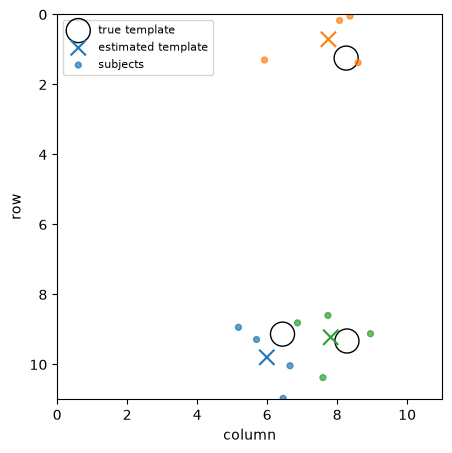

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
colors = plt.cm.tab10(np.arange(K))
true_c = truth["global_centers"]
ax.scatter(
    true_c[:, 1],
    true_c[:, 0],
    s=300,
    facecolors="none",
    edgecolors="k",
    label="true template",
)
ax.scatter(
    model.global_centers_[:, 1],
    model.global_centers_[:, 0],
    marker="x",
    s=120,
    c=colors,
    label="estimated template",
)
for s in range(n_sub):
    ax.scatter(
        model.centers_[s][:, 1],
        model.centers_[s][:, 0],
        c=colors,
        s=18,
        alpha=0.7,
        label="subjects" if s == 0 else None,
    )
ax.set_xlim(0, 11)
ax.set_ylim(11, 0)
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_aspect("equal")
ax.legend(fontsize=8)
plt.show()